# Comparing linear models, neural networks, and gradient boosting

Classification on city data and regression on house prices.

Saved outputs are from the original coursework run, before the small fixes in this copy. The notebooks have not been rerun.

The original printed reports call gradient boosting “Random Forest”; the code uses gradient boosting.


# Lab3: Evaluating Models

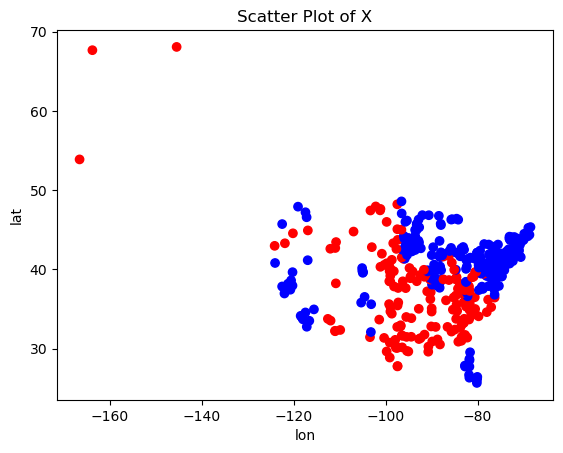

(100, 2) (100, 1)

In [ ]:
#sklearn Classification 
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
import matplotlib.pyplot as plt



ds = pd.read_csv('data/cities_USA.csv', delimiter=',')
#encode
label_encoder = LabelEncoder()
ds['vote'] = label_encoder.fit_transform(ds['vote'])

X = ds.iloc[:, 1:]  # First column is useless
X = X.drop(columns=["vote"], axis=1)
y = ds['vote']

X = pd.DataFrame(X)
y = pd.Series(y, name="vote")

# Use LabelEncoder to convert categorical values to numeric labels
label_encoder = LabelEncoder()
y_numeric = label_encoder.fit_transform(y)

# Scatter plot with color-coded dots based on y_test
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y_numeric, cmap='bwr', marker='o')
plt.title('Scatter Plot of X')
plt.xlabel('lon')
plt.ylabel('lat')
plt.show()



#Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)

print("\n\n" ,X_test.shape, y_test.shape)
#Standardize
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
#neual net 
clf_nn = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=42, max_iter=10000)
clf_nn.fit(X_train, y_train)

pred_nn = clf_nn.predict(X_test)

report_nn = classification_report(y_test, pred_nn)
conf_matrix_nn = confusion_matrix(y_test, pred_nn)
print("\nNeural Net Classification Report:\n", report_nn)
print("\nConfusion Matrix:\n", conf_matrix_nn)

Neural Net Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.84        57
           1       0.80      0.77      0.79        43

    accuracy                           0.82       100
   macro avg       0.82      0.81      0.82       100
weighted avg       0.82      0.82      0.82       100


Confusion Matrix:
 [[49  8]
 [10 33]]

In [ ]:
#gradient boosting
clf_gb = GradientBoostingClassifier(learning_rate=0.2, random_state=42)
clf_gb.fit(X_train, y_train)

pred_gb = clf_gb.predict(X_test)

report_gb = classification_report(y_test, pred_gb)
conf_matrix_gb = confusion_matrix(y_test, pred_gb)
print("\nGradient Boosting Classification Report:\n", report_gb)
print("\nConfusion Matrix:\n", conf_matrix_gb)

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.95      0.93        57
           1       0.93      0.88      0.90        43

    accuracy                           0.92       100
   macro avg       0.92      0.92      0.92       100
weighted avg       0.92      0.92      0.92       100


Confusion Matrix:
 [[54  3]
 [ 5 38]]

In [ ]:
#Logistic Regression
Log_R = LogisticRegression(random_state=43)
Log_R.fit(X_train, y_train)

pred_Log_R = Log_R.predict(X_test)

report_Log_R = classification_report(y_test, pred_Log_R)
conf_matrix_Log_R = confusion_matrix(y_test, pred_Log_R)
print("\nLog Reg Classification Report:\n", report_Log_R)
print("\nConfusion Matrix:\n", conf_matrix_Log_R)

Log Reg Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.84      0.73        57
           1       0.65      0.40      0.49        43

    accuracy                           0.65       100
   macro avg       0.65      0.62      0.61       100
weighted avg       0.65      0.65      0.63       100


Confusion Matrix:
 [[48  9]
 [26 17]]

In [ ]:
#sklearn Regression
import datetime
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from math import sqrt
from sklearn.linear_model import LinearRegression
import seaborn as sns
%matplotlib inline



df = pd.read_csv('data/kc_house_data.csv', delimiter=',')
#print(df.head())
df = df.drop(columns="date", axis=1)

#df["age_of_house"] = current_year - pd.to_datetime(df["yr_built"]).dt.year
print(df.head())
print("\nMEAN_CHARGE",  df['price'].mean())
print("\nMEDIAN_CHARGE", df["price"].median())

#Handling Outliers. We want mean and median to be close
index = 0    
#drop outliers, the wild points over 1M price(the number removed is printed below)
for i in range(0, len(df.price)):
    if df.price[i] > 1000000:
        index= index + 1
        df.drop(i, inplace = True)
        
print("index for the values > 1M (WildPoints): "  ,index ,"out of ",  len(df.price)+index)
df.reset_index(drop=True, inplace=True)


y = df['price']
X = df.drop(columns='price', axis=1)
#print(X, "\n\n", y)
print("\nNEW_MEAN_CHARGE",  df['price'].mean())
print("\nNEW_MEDIAN_CHARGE", df["price"].median())

#Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1)

#Standardize
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

id     price  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  7129300520  221900.0         3       1.00         1180      5650     1.0   
1  6414100192  538000.0         3       2.25         2570      7242     2.0   
2  5631500400  180000.0         2       1.00          770     10000     1.0   
3  2487200875  604000.0         4       3.00         1960      5000     1.0   
4  1954400510  510000.0         3       2.00         1680      8080     1.0   

   waterfront  view  condition  grade  sqft_above  sqft_basement  yr_built  \
0           0     0          3      7        1180              0      1955   
1           0     0          3      7        2170            400      1951   
2           0     0          3      6         770              0      1933   
3           0     0          5      7        1050            910      1965   
4           0     0          3      8        1680              0      1987   

   yr_renovated  zipcode      lat     long  sqft_living15  sqft_lot

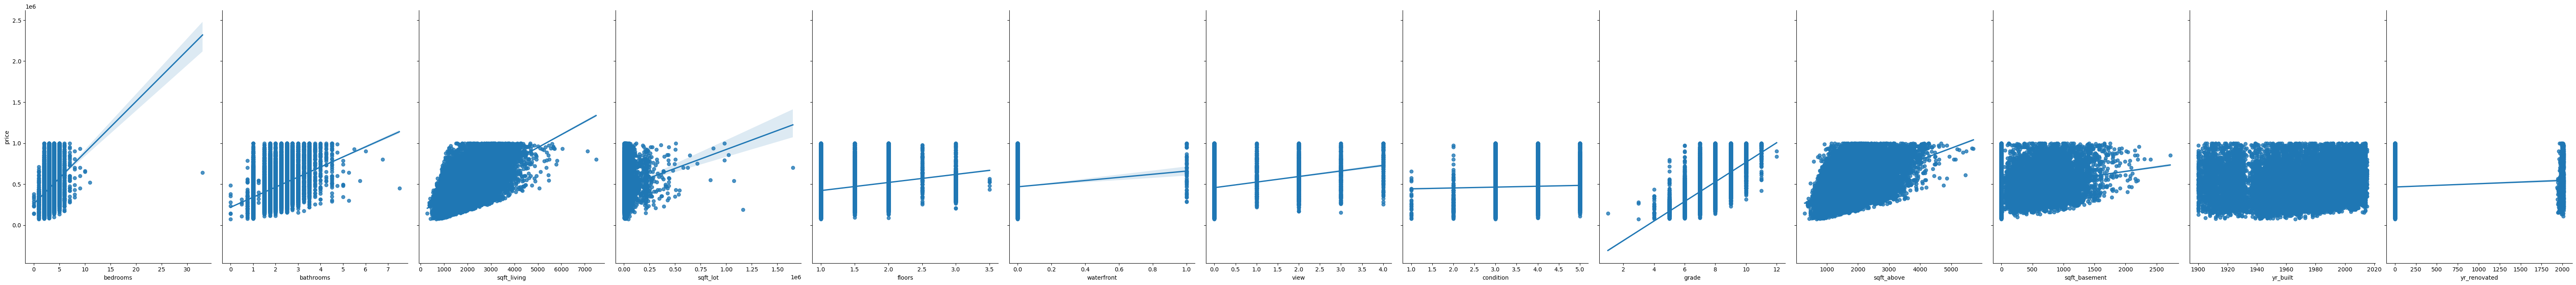

In [ ]:
#some plots to observe the data
feature_cols = [ u'bedrooms', u'bathrooms', u'sqft_living',
                u'sqft_lot', u'floors', u'waterfront', u'view', u'condition', u'grade',
                u'sqft_above', u'sqft_basement', u'yr_built', u'yr_renovated']

sns.pairplot(df,x_vars=feature_cols,y_vars="price",height=7,aspect=0.7,kind = 'reg')

In [ ]:
#neural net
NN = MLPRegressor(random_state=1, max_iter=10000) #many iterations. Waiting.....
NN.fit(X_train, y_train)

pred_NN = NN.predict(X_test)
rmse_NN = sqrt(mean_squared_error(pred_NN, y_test))
acc_NN = NN.score(X_test, y_test)

print("\nNN_RMSE\n" ,rmse_NN, "\nNN_R^2_SCORE\n", acc_NN)

NN_RMSE
 99928.74461624511 
NN_R^2_SCORE
 0.7347182874516991

In [ ]:
# Longer MLP run for comparison
NN = MLPRegressor(random_state=1, max_iter=15000) #with even more iterations. This longer run checks whether additional iterations change the fit.
NN.fit(X_train, y_train)

pred_NN = NN.predict(X_test)
rmse_NN = sqrt(mean_squared_error(pred_NN, y_test))
acc_NN = NN.score(X_test, y_test)

print("\nNN_RMSE\n" ,rmse_NN, "\nNN_R^2_SCORE\n", acc_NN)

# The original saved output for this longer run conflicts with the old
# convergence comment: RMSE was about 497,581 and R² was -5.58.
# The original saved output is shown below; this is not evidence of stable convergence.


NN_RMSE
 497581.3661554228 
NN_R^2_SCORE
 -5.577406237643618

In [ ]:
#linear Regr
LR = LinearRegression()
LR.fit(X_train, y_train)

pred_LR = LR.predict(X_test)
rmse_LR = sqrt(mean_squared_error(pred_LR, y_test))
acc_LR = LR.score(X_test, y_test)

print("\nLR_RMSE\n" ,rmse_LR, "\nLR_R^2_SCORE\n", acc_LR)

LR_RMSE
 108247.9300822082 
LR_R^2_SCORE
 0.6887096551647376

In [ ]:
#SGD Regressor
from sklearn.linear_model import SGDRegressor

sgd = SGDRegressor(max_iter=50000, random_state=42, epsilon=0.01)
sgd.fit(X_train, y_train)

pred_SGD = sgd.predict(X_test)
rmse_SGD = sqrt(mean_squared_error(pred_SGD, y_test))
acc_SGD = sgd.score(X_test, y_test)

print("\nSGD_RMSE\n" ,rmse_SGD, "\nSGD_R^2_SCORE\n", acc_SGD)

SGD_RMSE
 108466.37547945562 
SGD_R^2_SCORE
 0.687452013466368

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

#Gradient Boosting
gbr = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42, learning_rate=0.45) #after testing we found out
gbr.fit(X_train, y_train)                                                                          #what he best Learnin Rate is

pred_GBR = gbr.predict(X_test)
rmse_GBR = sqrt(mean_squared_error(pred_GBR, y_test))
acc_GBR = gbr.score(X_test, y_test)

print("\nGBR_RMSE\n" ,rmse_GBR, "\nGBR_R^2_SCORE\n", acc_GBR)
#nailed it

GBR_RMSE
 72236.60262079493 
GBR_R^2_SCORE
 0.8613751547827275

# Comments
## In both classification and regression we observed the same performance among the three:
* Gradient Boosting was better than both 
* While the Neural Network came seccond 
* The (ordinary) Linear Regression and Logistic Regression came last